<a href="https://colab.research.google.com/github/alijon070/computer_vision/blob/main/pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [78]:
pip install torch


In [79]:
import torch

In [80]:
print(torch.__version__)

2.11.0+cu130


In [81]:
print("CUDA available:", torch.cuda.is_available())

CUDA available: True


In [82]:
scalar = torch.tensor(5) # 0D
print("scalar:", scalar)
print("Shape:", scalar.shape)

scalar: tensor(5)
Shape: torch.Size([])


In [83]:
vector = torch.tensor([1, 2, 3]) # 01
print("vector:", vector)
print("Shape:", vector.shape)
print("Size:", vector.size())



vector: tensor([1, 2, 3])
Shape: torch.Size([3])
Size: torch.Size([3])


In [84]:
MATRIX = torch.tensor([[1, 2, 3], [1, 2, 3]]) # 01
print("MATRIX:", MATRIX)
print("Shape:", MATRIX.shape)


MATRIX: tensor([[1, 2, 3],
        [1, 2, 3]])
Shape: torch.Size([2, 3])


In [85]:
tensor3d = torch.stack([MATRIX, MATRIX + 10])
print('tensor3d:', tensor3d)
print("Shape:", tensor3d.shape)


tensor3d: tensor([[[ 1,  2,  3],
         [ 1,  2,  3]],

        [[11, 12, 13],
         [11, 12, 13]]])
Shape: torch.Size([2, 2, 3])


In [86]:
random_numbers = torch.rand(3, 4)
print("random_numbers:", random_numbers)
print("Shape:", random_numbers.shape)
print('Data type:', random_numbers.dtype)

random_numbers: tensor([[0.3829, 0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408, 0.1332],
        [0.9346, 0.5936, 0.8694, 0.5677]])
Shape: torch.Size([3, 4])
Data type: torch.float32


In [87]:
print('Zeros:', torch.zeros(3, 3))

Zeros: tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])


In [88]:
print('Ones:', torch.ones(2, 4))


Ones: tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.]])


In [89]:
x =torch.tensor([[1, 2],
                 [3, 4]])

y =torch.tensor([[5, 6],
                 [7, 8]])

# Element-wise addition
print('Addition:', x + y)

print('================')

print('Multipication:', x * y)

print('================')

print('Matrix @ Multipication:', x @ y)



#x
# [[1, 2],
#  [3, 4]]

# #y
#  [[5, 6],
#   [7, 8]]




Addition: tensor([[ 6,  8],
        [10, 12]])
Multipication: tensor([[ 5, 12],
        [21, 32]])
Matrix @ Multipication: tensor([[19, 22],
        [43, 50]])


In [90]:
# import PyTorch and matplotlib
import torch
from torch import nn # nn contains all of PyTorch's building blocks for neural networks
import matplotlib.pyplot as plt

In [91]:
# Setup device agnostic code
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')

Using device: cuda


In [92]:
# create weight and bias
weight = 0.7
bias = 0.3

# create range values
start = 0
end = 1
step = 0.02

# create X and y (features and labels)
X = torch.arange(start, end, step).unsqueeze(dim=1) # without squeeze, errors will happen later on (shapes within linear layers)
y = weight * X * bias

# linear regression: y = w * x + b

print("X:", X)
print("y:", y)

# Split data
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)



X: tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800],
        [0.2000],
        [0.2200],
        [0.2400],
        [0.2600],
        [0.2800],
        [0.3000],
        [0.3200],
        [0.3400],
        [0.3600],
        [0.3800],
        [0.4000],
        [0.4200],
        [0.4400],
        [0.4600],
        [0.4800],
        [0.5000],
        [0.5200],
        [0.5400],
        [0.5600],
        [0.5800],
        [0.6000],
        [0.6200],
        [0.6400],
        [0.6600],
        [0.6800],
        [0.7000],
        [0.7200],
        [0.7400],
        [0.7600],
        [0.7800],
        [0.8000],
        [0.8200],
        [0.8400],
        [0.8600],
        [0.8800],
        [0.9000],
        [0.9200],
        [0.9400],
        [0.9600],
        [0.9800]])
y: tensor([[0.0000],
        [0.0042],
        [0.0084],
        [0.0126],
        [0.0168],
   

(40, 40, 10, 10)

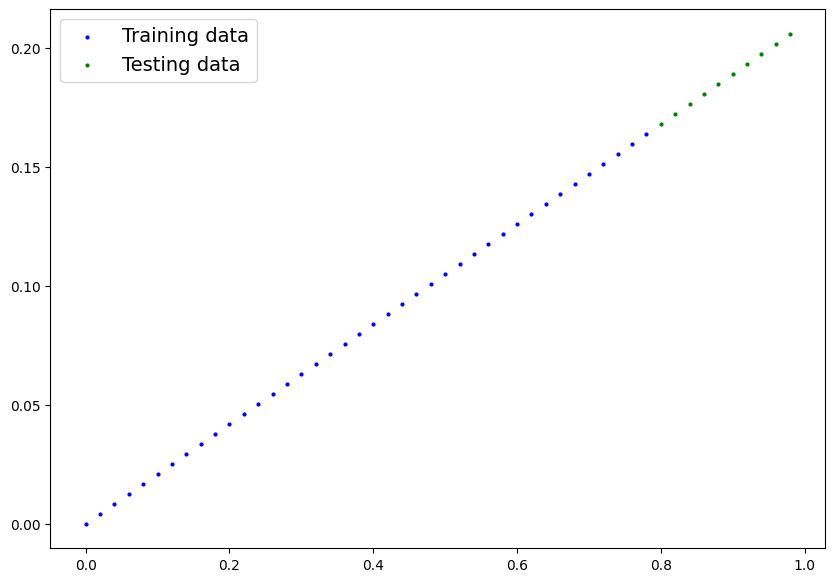

In [93]:
def plot_predictions(train_data=X_train,
                    train_labels=y_train,
                    test_data=X_test,
                    test_labels=y_test,
                    predictions=None):
  plt.figure(figsize=(10, 7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c='b', s=4, label='Training data')

  # Plot test data in green
  plt.scatter(test_data, test_labels, c='g', s=4, label='Testing data')

  if predictions is not None:
    # Plot the predictions in red (predictions were made on the test data)
    plt.scatter(test_data, predictions, c='r', s=4, label='Predictions')

  # Show the legend
  plt.legend(prop = {'size': 14})

plot_predictions()


In [94]:
# Subclass nn.Module to make our model

class LinearRegressionModelV2(nn.Module):
  def __init__(self):
    super().__init__()
    # Use nn.Linear for creating the model parameters
    self.linear_layer = nn.Linear(in_features=1,
                                  out_features=1)

  # Define forward computation (input data x flows through nn.Linear())
  def forward(self, x: torch.Tensor) -> torch.Tensor:
      return self.linear_layer(x)

# Set manual seed when creating the model (this isn't always needed but is used for demonstrative purposes, try comenting it out and seeing when happens)
torch.manual_seed(42)
model_1 = LinearRegressionModelV2()
model_1, model_1.state_dict()


(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [95]:
# create loss function and optimizer
loss_fn = nn.L1Loss()

# create optimizer
optimizer = torch.optim.SGD(params=model_1.parameters(),
                            lr=0.01)

Text(0.5, 1.0, 'Predictions before training (red = random guesses)')

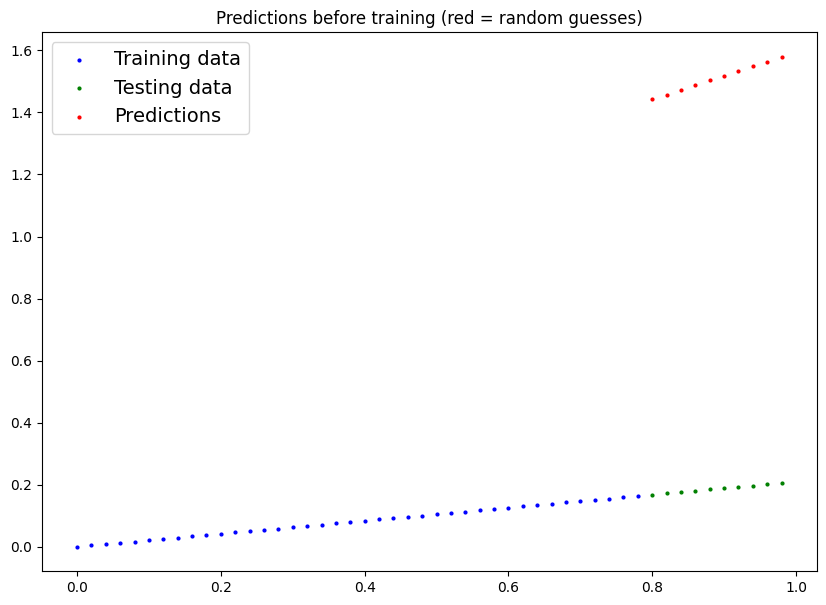

In [96]:
# See model's untrained predictions (on test set)

model_1.eval()
with torch.inference_mode():
  untrained_preds = model_1(X_test)

plot_predictions(predictions=untrained_preds)
plt.title("Predictions before training (red = random guesses)")

In [97]:
# set the numbers of epochs
epochs = 1000

# Put data on the available device
# without this, error will happen (not all model/data on device)
X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)
model_1 = model_1.to(device)

for epoch in range(epochs):
  ### Training
  model_1.train() # train mode is on by default after construction

  # 1. Forward pass
  y_pred = model_1(X_train)

  # 2. Calculate loss
  loss = loss_fn(y_pred, y_train)


  # 3. Optimizer zero grad
  optimizer.zero_grad()

  # 4. Loss backward
  loss.backward()

  # 5. Optimizer step
  optimizer.step()

  ### Testing
  model_1.eval()
  # Forward pass
  with torch.inference_mode():
    test_pred = model_1(X_test)
  #Calculate loss
    test_loss = loss_fn(test_pred, y_test)

  if epoch % 100 == 0:
    print(f"Epoch: {epoch} | Train loss: {loss} | Test loss: {test_loss}")

#

Epoch: 0 | Train loss: 1.0462779998779297 | Test loss: 1.310076355934143
Epoch: 100 | Train loss: 0.03575398400425911 | Test loss: 0.08907495439052582
Epoch: 200 | Train loss: 0.007542048580944538 | Test loss: 0.008428367786109447
Epoch: 300 | Train loss: 0.007542048580944538 | Test loss: 0.008428367786109447
Epoch: 400 | Train loss: 0.007542048580944538 | Test loss: 0.008428367786109447
Epoch: 500 | Train loss: 0.007542048580944538 | Test loss: 0.008428367786109447
Epoch: 600 | Train loss: 0.007542048580944538 | Test loss: 0.008428367786109447
Epoch: 700 | Train loss: 0.007542048580944538 | Test loss: 0.008428367786109447
Epoch: 800 | Train loss: 0.007542048580944538 | Test loss: 0.008428367786109447
Epoch: 900 | Train loss: 0.007542048580944538 | Test loss: 0.008428367786109447


In [98]:
# turn model into evaluation mode
model_1.eval()

# make predictions on the test data
with torch.inference_mode():
  y_preds = model_1(X_test)
y_preds



tensor([[0.1625],
        [0.1668],
        [0.1711],
        [0.1754],
        [0.1797],
        [0.1840],
        [0.1883],
        [0.1926],
        [0.1969],
        [0.2012]], device='cuda:0')

TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.

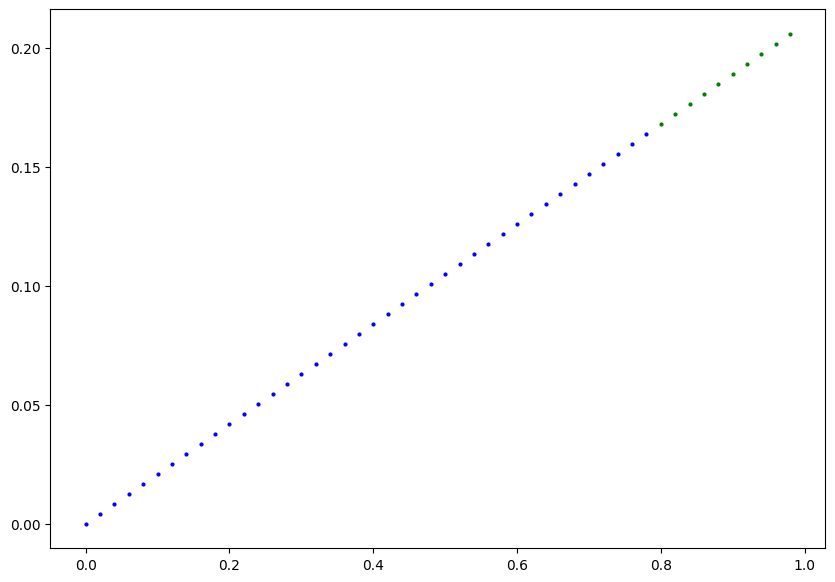

In [102]:
# plot predictions vs truth
plot_predictions(predictions=y_preds)

In [104]:
torch.save(model_1.state_dict(), 'trained_model.pth')

In [105]:
loaded_model = LinearRegressionModelV2()

loaded_model.load_state_dict(torch.load('/content/trained_model.pth'))

loaded_model.eval()

LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)